In [3]:
%pip install pandas numpy matplotlib seaborn scikit-learn joblib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [4]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully")

Libraries imported successfully


In [5]:
df = pd.read_csv("bank-full.csv", sep=";")

df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [4]:
print("Shape:", df.shape)

print("Columns:", df.columns.tolist())

df.info()

Shape: (45211, 17)
Columns: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null 

In [6]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [7]:
df.isnull().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

In [8]:
print("Duplicates:", df.duplicated().sum())

df = df.drop_duplicates()

Duplicates: 0


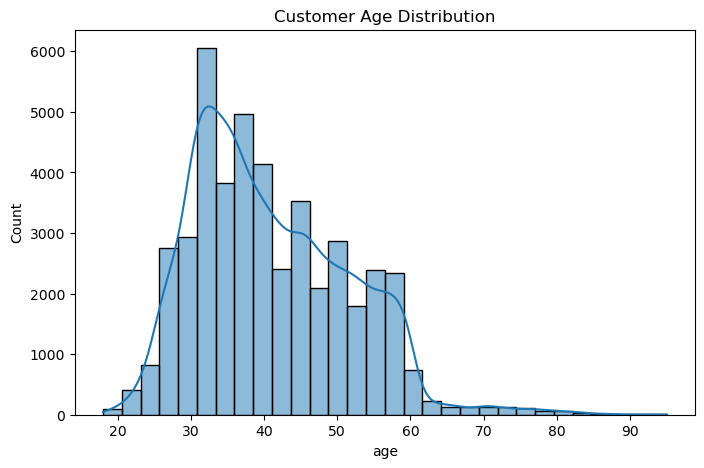

In [9]:
plt.figure(figsize=(8,5))

sns.histplot(df['age'], bins=30, kde=True)

plt.title("Customer Age Distribution")

plt.show()

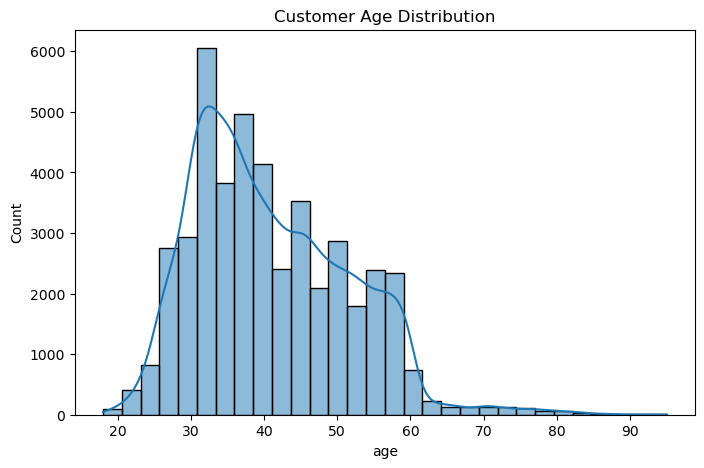

In [10]:
plt.figure(figsize=(8,5))

sns.histplot(df['age'], bins=30, kde=True)

plt.title("Customer Age Distribution")

plt.show()

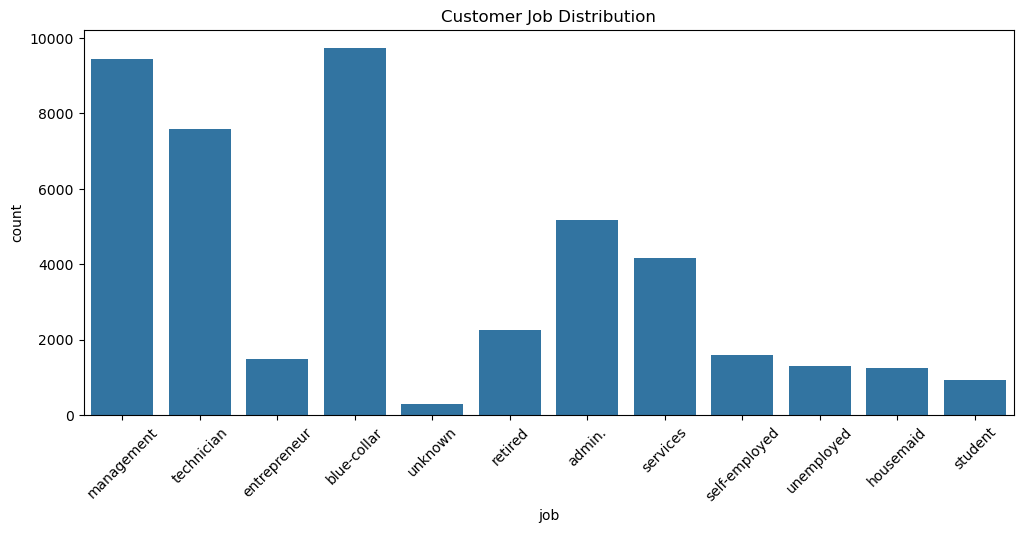

In [11]:
plt.figure(figsize=(12,5))

sns.countplot(data=df, x='job')

plt.xticks(rotation=45)

plt.title("Customer Job Distribution")

plt.show()

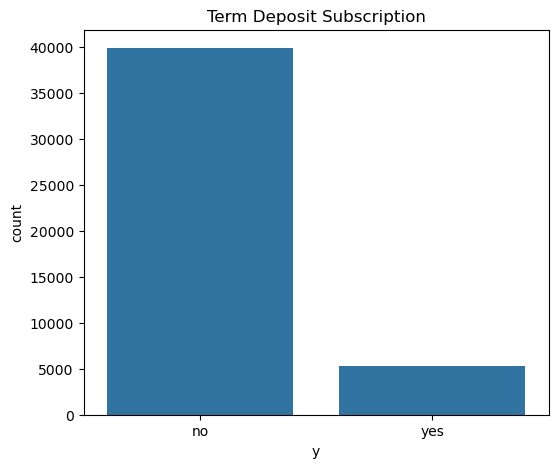

In [12]:
plt.figure(figsize=(6,5))

sns.countplot(data=df, x='y')

plt.title("Term Deposit Subscription")

plt.show()

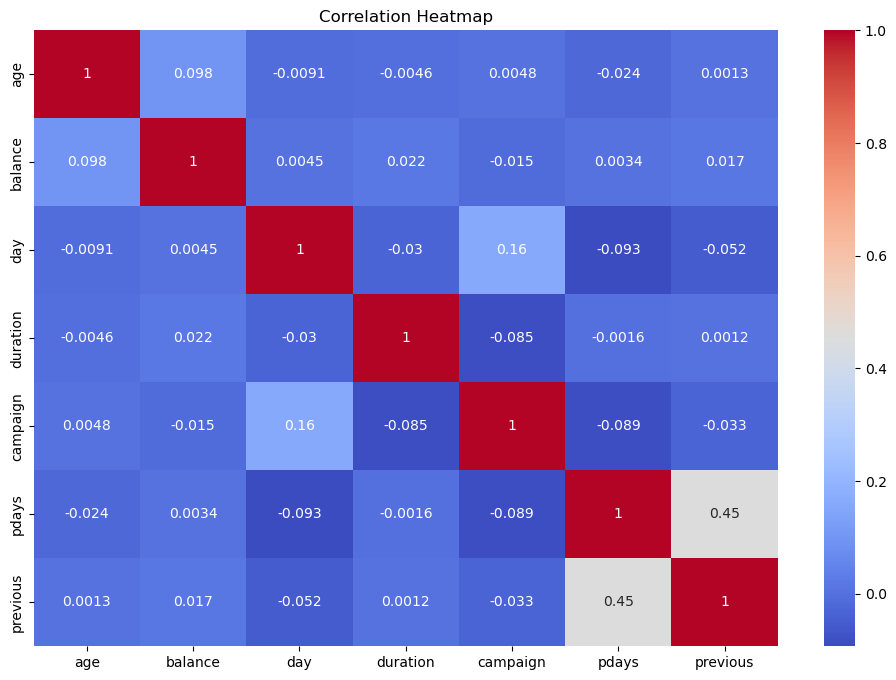

In [12]:
plt.figure(figsize=(12,8))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title("Correlation Heatmap")

plt.show()

In [13]:
X = df.drop(['y', 'duration'], axis=1)

y = df['y'].map({'no': 0, 'yes': 1})

print("Features:", X.shape)

print("Target:", y.shape)

Features: (45211, 15)
Target: (45211,)


In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)

print("Testing:", X_test.shape)

Training: (36168, 15)
Testing: (9043, 15)


In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.ensemble import RandomForestClassifier

num_cols = X.select_dtypes(include=np.number).columns

cat_cols = X.select_dtypes(exclude=np.number).columns

preprocessor = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), num_cols),

    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]), cat_cols)
])

model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight='balanced',
        n_jobs=-1
    ))
])

print("Model created successfully")

Model created successfully


In [16]:
model.fit(X_train, y_train)

print("Model training completed")

Model training completed


In [17]:
y_pred = model.predict(X_test)

print(y_pred[:10])

[0 0 0 0 0 0 0 1 0 0]


In [18]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy * 100, "%")

Accuracy: 89.32876257879022 %


In [19]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.90      0.98      0.94      7985
           1       0.63      0.21      0.31      1058

    accuracy                           0.89      9043
   macro avg       0.77      0.60      0.63      9043
weighted avg       0.87      0.89      0.87      9043



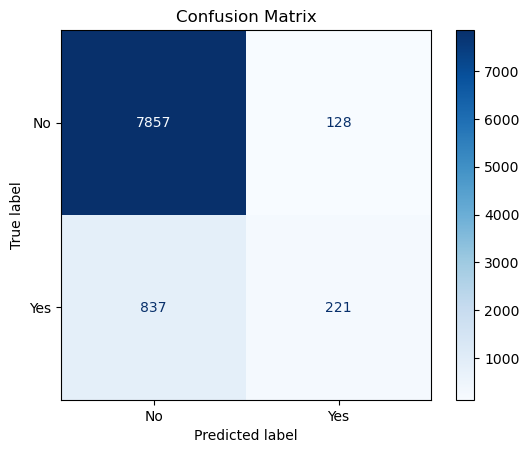

In [20]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=['No', 'Yes'],
    cmap='Blues'
)

plt.title("Confusion Matrix")

plt.show()

In [21]:
import joblib

joblib.dump(model, 'bank_marketing_model.pkl')

print("Model saved successfully")

Model saved successfully


## PRCP-1000 – PORTUGUESE BANK MARKETING

**Domain:** Finance / Banking  
**Project Type:** Data Analysis and Machine Learning  
**Programming Language:** Python  
**Dataset:** Bank Additional Full Dataset 
**Target Variable:** y (Yes / No)

---

 1. ABSTRACT

The Portuguese Bank Marketing project focuses on analyzing direct marketing campaigns conducted by a Portuguese banking institution between May 2008 and November 2010.

The main objective is to understand customer behavior and predict whether a customer will subscribe to a term deposit after receiving a marketing call.

Python libraries such as Pandas, NumPy, Matplotlib, Seaborn, and Scikit-learn are used for data cleaning, exploratory data analysis, visualization, and machine learning.

The project also provides business recommendations to help the bank improve its marketing strategies, identify potential customers, and increase term deposit subscriptions.

## 2. PROBLEM STATEMENT

The banking institution conducts marketing campaigns through telephone calls to promote term deposit products among existing customers.

However, contacting every customer requires time, money, and resources. Not every customer is interested in purchasing the product.

Therefore, the bank needs a data-driven approach to identify customers who are more likely to subscribe to a term deposit.

This project analyzes customer information and previous campaign details to develop a predictive model that helps the marketing team make better decisions.

## 3. OBJECTIVES

The main objectives are:

1. Perform complete data analysis on the bank marketing dataset.
2. Understand customer characteristics and behavior.
3. Identify important factors influencing term deposit subscriptions.
4. Perform data cleaning and exploratory data analysis.
5. Develop machine learning models to predict customer subscriptions.
6. Compare different machine learning algorithms.
7. Provide useful suggestions to improve marketing campaigns.

## 4. DATASET DESCRIPTION

The dataset contains information about customers, their financial status, previous marketing interactions, and campaign results.

**Dataset file:** `bank-additional-full.csv`

**Dataset location:** `Data/bank-additional/bank-additional-full.csv`

**Number of attributes:** 20, including the target variable.

### Input Variables

| Attribute | Description |
|---|---|
| age | Customer age |
| job | Type of job |
| marital | Marital status |
| education | Education level |
| default | Credit default status |
| housing | Housing loan status |
| loan | Personal loan status |
| contact | Contact communication type |
| month | Last contact month |
| day_of_week | Last contact day |
| duration | Last contact duration |
| campaign | Number of contacts during current campaign |
| pdays | Days since previous campaign contact |
| previous | Number of previous contacts |
| poutcome | Previous campaign outcome |
| emp.var.rate | Employment variation rate |
| cons.price.idx | Consumer price index |
| cons.conf.idx | Consumer confidence index |
| euribor3m | Three-month Euribor rate |

**Target variable:** `y`

- Yes – Customer subscribed to a term deposit.
- No – Customer did not subscribe.

## 5. TECHNOLOGIES USED

- Python
- Visual Studio Code
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Joblib

## 6. DATA CLEANING AND PREPROCESSING

Data cleaning is performed to improve the quality of the dataset before analysis.

The following operations are performed:

1. Load the CSV dataset using Pandas.
2. Check the number of rows and columns.
3. Identify missing values.
4. Check and remove duplicate records.
5. Identify numerical and categorical variables.
6. Handle categorical values such as unknown.
7. Encode categorical variables using One-Hot Encoding.
8. Scale numerical variables where required.

The target variable is converted into numerical format:

- Yes = 1
- No = 0

## 7. EXPLORATORY DATA ANALYSIS (EDA)

Exploratory Data Analysis is performed to understand customer characteristics and identify patterns in the dataset.

### 7.1 Age Analysis

Customer age is analyzed to understand which age groups are represented in the marketing campaign.

A histogram is used to visualize the age distribution.

### 7.2 Job Analysis

Customers are grouped according to their occupations, such as:

- Admin
- Technician
- Blue-collar
- Management
- Services
- Retired
- Student
- Entrepreneur

The subscription rate is compared across job categories.

### 7.3 Education Analysis

Customer education levels are analyzed to understand whether education is associated with term deposit subscriptions.

### 7.4 Marital Status Analysis

Customers are classified into married, single, and divorced categories.

The subscription rate is compared across these groups.

### 7.5 Contact Analysis

The communication methods are analyzed:

- Cellular
- Telephone

This helps the bank understand how communication channels relate to campaign outcomes.

### 7.6 Campaign Analysis

The number of contacts made during the campaign is analyzed to understand the relationship between contact frequency and customer subscription.

## 8. STATISTICAL ANALYSIS

Statistical analysis is performed on numerical variables using:

- Mean
- Median
- Mode
- Standard deviation
- Minimum
- Maximum

These statistical measures help understand customer age, campaign contacts, previous contacts, and economic indicators.

## 9. DATA VISUALIZATION

The following visualizations are generated:

1. Customer age distribution.
2. Term deposit subscription distribution.
3. Job-wise subscription rate.
4. Education-wise subscription rate.
5. Marital-status subscription rate.
6. Campaign contact distribution.
7. Contact method analysis.
8. Correlation heatmap.
9. Confusion matrix.

These charts help identify patterns and relationships in the dataset.

## 10. MACHINE LEARNING MODEL

A predictive model is developed to identify customers who are likely to subscribe to a term deposit.

### 10.1 Target Variable

The target variable is `y`.

- 1 = Yes
- 0 = No

### 10.2 Feature Selection

Customer age, job, marital status, education, loan details, contact information, campaign details, and economic indicators are used as input features.

The `duration` variable is excluded from the realistic predictive model because call duration is only known after the phone call. Including it could cause data leakage.

### 10.3 Train-Test Split

The dataset is divided into:

- 80% Training Data
- 20% Testing Data

The training data is used to train the model, while the testing data is used to evaluate its performance.

### 10.4 Algorithms Used

**1. Logistic Regression**

Logistic Regression is used for binary classification to predict whether a customer will subscribe or not.

**2. Random Forest**

Random Forest combines multiple decision trees to improve prediction performance and handle complex relationships in customer data.

### 10.5 Model Evaluation

The following evaluation metrics are used:

| Metric | Purpose |
|---|---|
| Accuracy | Overall correct predictions |
| Precision | Correct positive predictions |
| Recall | Actual subscribers identified |
| F1-score | Balance between precision and recall |
| ROC-AUC | Ability to distinguish subscribers from non-subscribers |

F1-score and recall for the Yes class are especially important because the dataset contains fewer subscribers than non-subscribers.

The best model is selected based on the positive-class F1-score.

## 11. CUSTOMER SUBSCRIPTION PREDICTION

The trained machine learning model predicts whether a customer is likely to subscribe to a term deposit.

The output is classified into two categories:

- **Yes:** Customer is predicted to subscribe.
- **No:** Customer is predicted not to subscribe.

The model can help the bank prioritize customers who have a higher predicted probability of subscribing.

Predictions should support marketing decisions rather than guarantee customer behavior.

## 12. BUSINESS SUGGESTIONS TO THE BANK MARKETING TEAM

The following recommendations can help improve marketing campaign performance.

### 1. Target Potential Customers

Use machine learning predictions to identify customers with a higher likelihood of subscribing.

### 2. Improve Customer Segmentation

Divide customers into groups based on age, occupation, education, and previous campaign results.

### 3. Choose Suitable Contact Methods

Analyze the performance of cellular and telephone communication channels and allocate campaign resources accordingly.

### 4. Improve Campaign Timing

Analyze previous campaign results to identify suitable months and days for contacting customers.

### 5. Avoid Repeated Calls

Avoid unnecessary repeated calls to customers who have already received many contacts.

### 6. Focus on Previous Campaign Results

Use previous campaign outcomes to improve customer targeting strategies.

### 7. Provide Clear Product Information

Explain the benefits, interest rates, terms, and conditions of term deposits clearly.

### 8. Monitor Campaign Performance

Regularly evaluate subscription rates, marketing costs, and customer responses.

### 9. Respect Customer Preferences

Respect customer consent, opt-out requests, and communication preferences.

### 10. Continuously Improve the Model

Update the predictive model periodically using new campaign data.

## 13. KEY FINDINGS

The analysis is designed to identify:

1. The distribution of customers across different age groups.
2. The relationship between occupation and subscription.
3. Subscription patterns across education and marital-status groups.
4. Differences between communication channels.
5. The relationship between campaign contacts and subscription.
6. The importance of previous campaign outcomes.
7. The influence of economic indicators on customer behavior.
8. The machine learning model that performs best on the test data.

Actual findings and numerical values should be inserted after running the Python program.

## 14. CONCLUSION

The Portuguese Bank Marketing project demonstrates how data analysis and machine learning can support banking marketing decisions.

Exploratory Data Analysis helps understand customer characteristics, campaign performance, and subscription patterns.

Machine learning algorithms such as Logistic Regression and Random Forest are used to predict customer subscription behavior.

The predictive model can help the bank identify potential customers, improve campaign targeting, reduce unnecessary calls, and use marketing resources more effectively.

Overall, this project demonstrates the importance of data-driven decision-making in the banking and finance domain.

## 15. FUTURE ENHANCEMENTS

1. Develop a web application using Flask.
2. Create an interactive dashboard using Power BI.
3. Add real-time customer subscription predictions.
4. Compare additional machine learning algorithms.
5. Use advanced hyperparameter tuning.
6. Monitor model performance using new marketing campaign data.